YOUSSEF - Linear Regression + Decision Tree

 Data Loaded: (250, 9)
  Property_ID        Location Property_Type  Area_SqM  Bedrooms  Bathrooms  \
0    PROP-100       Nasr City     Penthouse       246         2          1   
1    PROP-101  5th Settlement        Duplex       170         4          2   
2    PROP-102           Maadi         Villa       281         1          2   
3    PROP-103  5th Settlement         Villa        98         1          3   
4    PROP-104  5th Settlement     Apartment       118         5          1   

   Price_EGP Is_Sold  Days_On_Market  
0   12380726      No              48  
1    7715140      No              60  
2    5237973     Yes             160  
3    3702575      No             115  
4    8111653     Yes             138  

After Encoding: (250, 13)
Columns: ['Area_SqM', 'Bedrooms', 'Bathrooms', 'Price_EGP', 'Is_Sold', 'Days_On_Market', 'Location_Maadi', 'Location_Nasr City', 'Location_New Cairo', 'Location_Sheikh Zayed', 'Property_Type_Duplex', 'P

scaler.pkl saved

MODEL 1: Linear Regression
MAE:  3,157,736.92
RMSE: 3,866,099.97
R²:   -0.0333

MODEL 2: Decision Tree
MAE:  3,583,859.07
RMSE: 4,619,457.28
R²:   -0.4752

 results_youssef.csv saved
               Model           MAE          RMSE        R2
0  Linear Regression  3.157737e+06  3.866100e+06 -0.033264
1      Decision Tree  3.583859e+06  4.619457e+06 -0.475187


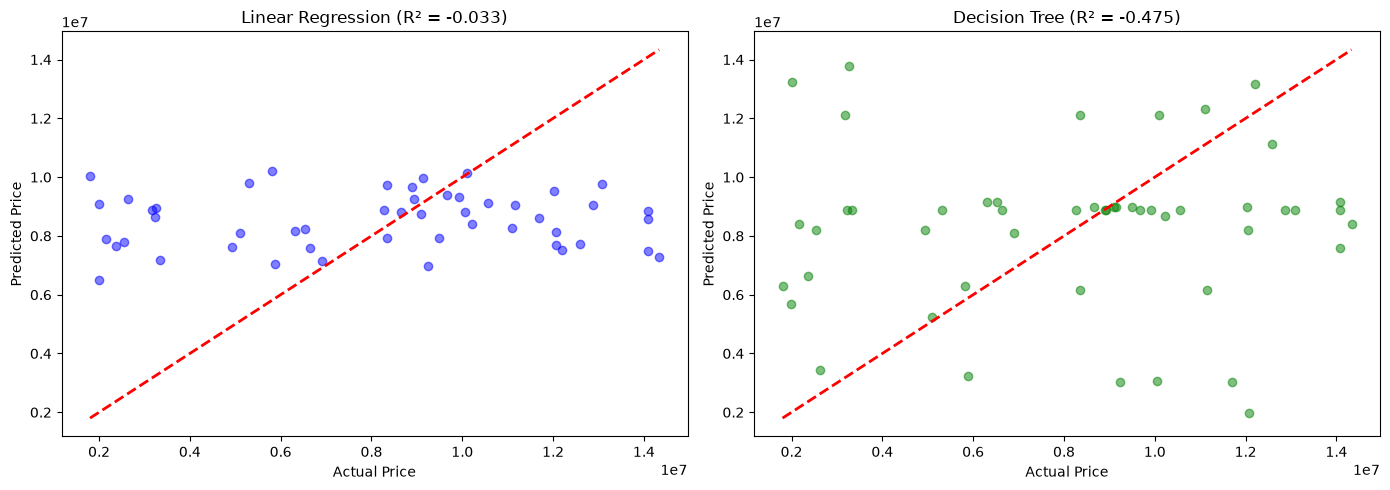

youssef_predictions.png saved

YOUSSEF - DONE WITH MODELS


In [3]:
# File: 01_youssef_linear_dt.ipynb
# Author: Youssef
# Models: Linear Regression + Decision Tree
# -----------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("YOUSSEF - Linear Regression + Decision Tree")
print("=" * 60)

# -----------------------------------------------
# 1. Load Data

df = pd.read_csv('../../1_Data/cleaned_data.csv')
print(f"\n Data Loaded: {df.shape}")
print(df.head())

# -----------------------------------------------
# 2. Preprocessing

df = df.drop('Property_ID', axis=1)
df['Is_Sold'] = df['Is_Sold'].map({'Yes': 1, 'No': 0})

# Encoding
df_encoded = pd.get_dummies(df, columns=['Location', 'Property_Type'], drop_first=True)
print(f"\nAfter Encoding: {df_encoded.shape}")
print(f"Columns: {df_encoded.columns.tolist()}")

# -----------------------------------------------
# 3. Features & Target

X = df_encoded.drop(['Price_EGP', 'Is_Sold'], axis=1)
y = df_encoded['Price_EGP']

print(f"\nFeatures: {X.columns.tolist()}")
print(f"Target: Price_EGP")

# ----------------------------------------------
# 4. Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")

# ----------------------------------------------
# 5. Scaling

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

joblib.dump(scaler, 'scaler.pkl')
print("scaler.pkl saved")

# ----------------------------------------------
# 6. Linear Regression

print("\n" + "=" * 60)
print("MODEL 1: Linear Regression")
print("=" * 60)

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)

lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_r2 = r2_score(y_test, lr_pred)

print(f"MAE:  {lr_mae:,.2f}")
print(f"RMSE: {lr_rmse:,.2f}")
print(f"R²:   {lr_r2:.4f}")

# ----------------------------------------------
# 7. Decision Tree

print("\n" + "=" * 60)
print("MODEL 2: Decision Tree")
print("=" * 60)

dt = DecisionTreeRegressor(random_state=42, max_depth=10)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_pred))
dt_r2 = r2_score(y_test, dt_pred)

print(f"MAE:  {dt_mae:,.2f}")
print(f"RMSE: {dt_rmse:,.2f}")
print(f"R²:   {dt_r2:.4f}")

# ----------------------------------------------
# 8. Save Results

results_youssef = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree'],
    'MAE': [lr_mae, dt_mae],
    'RMSE': [lr_rmse, dt_rmse],
    'R2': [lr_r2, dt_r2]
})

results_youssef.to_csv('results_youssef.csv', index=False)
print("\n results_youssef.csv saved")
print(results_youssef)

# ----------------------------------------------
# 9. Visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, lr_pred, alpha=0.5, color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].set_title(f'Linear Regression (R² = {lr_r2:.3f})')

axes[1].scatter(y_test, dt_pred, alpha=0.5, color='green')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_xlabel('Actual Price')
axes[1].set_ylabel('Predicted Price')
axes[1].set_title(f'Decision Tree (R² = {dt_r2:.3f})')

plt.tight_layout()
plt.savefig('youssef_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print("youssef_predictions.png saved")

print("\n" + "=" * 60)
print("YOUSSEF - DONE WITH MODELS")
print("=" * 60)